In [6]:
import panel as pn
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import os
from scipy.optimize import curve_fit

from matipo import SEQUENCE_DIR, GLOBALS_DIR
from matipo.sequence import Sequence
from matipo.util.autophase import autophase
from matipo.util.decimation import decimate
from matipo.util.fft import fft_reconstruction
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from matipo.util.pulseshape import calc_soft_pulse
from matipo.util.fft import fft_reconstruction
from matipo.util.fft import get_freq_spectrum
# progress_handler for Sequence.run() that simply prints the progress
def print_progress(p, l):
    print(p, '/', l)

In [2]:
from matipo import SEQUENCE_DIR, GLOBALS_DIR
from matipo.sequence import Sequence

from matipo.util.fft import fft_reconstruction
from matipo.util.fft import get_freq_spectrum

import os
import numpy as np
from bokeh.plotting import figure
import panel as pn
import asyncio
import traceback
from panel.io.state import state
# from daisy_wheels.user_interface.general import general_functions

from user_interface.general import general_functions
from user_interface.panes import panes
from user_interface.updating import updating
from user_interface.oneDfunctions import oneDfunctions
from user_interface.panel import panel_functions
from user_interface.run_seq import run_pulse_sequence
from user_interface.layout import panel_layout
from user_interface.threeDfunctions import threeDfunctions
from user_interface.buttons.btn_control import ButtonController


from pathlib import Path
from datetime import date, datetime
from panel.io.state import state

pulse_file = general_functions.get_yaml_info(info_name = 'seqnames.yaml', file = GLOBALS_DIR)["measure_ec"] 

file = general_functions.get_yaml_info(info_name = 'file.yaml', file = GLOBALS_DIR)["file"] # where you want the global parameters to be taken from 
pre_file = general_functions.get_yaml_info(info_name = 'prefiles.yaml', file = GLOBALS_DIR)["measure_ec"] # where the pulse file lives

print(pre_file)

C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/daisy_wheels/dashboards_/eddy_measure/


In [10]:
seq = Sequence('measure.py')

# load relevant global variables
seq.loadpar(GLOBALS_DIR+'frequency_tx0.yaml')
seq.loadpar(GLOBALS_DIR+'shims.yaml')

g_val = 0.1

seq.setpar(
    n_scans = 1,
    a_pulse=0.45, 
    t_pulse=30e-6,

    t_dw = 10e-6,
    n_samples = 100,
    t_acq_delay = 100e-6,
    t_grad = 10.0,
    t_ramp = 1e-3,
    t_wait = 8e-3,
    n_pulses = 30,
    t_end = 10.0, 
    t_next = 1, # wait between scans 
    g_read = (0,0,g_val),
    # g_read = (0,g_val,0),
    # g_read = (g_val,0,0),
    tx_chan = 0,
    rx_chan_list = (3,1,0),
    pre_emphasis = False,
    b0 = False,
    # file = GLOBALS_DIR,
)

pn.extension()
print(seq.par)
y = await seq.run(progress_handler=print_progress)

ParameterSet(n_scans=1, f=10000000.0, a_pulse=0.45, t_pulse=3e-05, t_dw=1e-05, n_samples=100, n_pulses=30, t_acq_delay=0.0001, g_read=array([0. , 0. , 0.1]), t_grad_spacing=1e-05, t_grad=10.0, t_ramp=0.001, t_wait=0.008, t_end=10.0, t_next=1.0, pre_emphasis=False, b0=False, offsets=array([0., 0., 0., 0.]), tx_chan=0, rx_chan_list=array([3., 1., 0.]), file_cals='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/globals/', file_pars='C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/globals/')


DEBUG:measure:B0 uses ideal gradient


C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/globals/eddy_Enew.yaml
C:/Users/halesda/OneDrive - Victoria University of Wellington - STAFF/Desktop/kahu-workspace/globals/eddy_B0new.yaml


DEBUG:measure:Pre-emphasis OFF
DEBUG:measure:B0 OFF


B0 cal: 22499.99999999999 Hz/DAC
 G_cal: {'X': 1386806.596701649, 'Y': 2359703.084965453, 'Z': 1933006.7109302483} Hz/m
par.n_pulses = 30
len(waits_pulses) = 29
len(i_pulse) = 31
acq_starts = 31
0.001151482 / 7.008730999903833
0.101683777 / 7.072000999901438
0.201999911 / 7.172660999897627
0.302707468 / 7.273790999893799
0.403080962 / 7.373400999890028
0.503452666 / 7.473010999886257
0.604173223 / 7.575210999882388
0.705018832 / 7.675870999878577
0.805369885 / 7.775470999874806
0.905964421 / 7.8776409998709385
1.006353545 / 7.977270999867167
1.106708739 / 8.076870999863397
1.207324785 / 8.179050999859529
1.307700929 / 8.278680999855757
1.408029423 / 8.378280999851986
1.508641349 / 8.480460999848118
1.609009613 / 8.580080999844347
1.709912622 / 8.679690999840576
1.810513808 / 8.781850999836708
1.910868292 / 8.881480999832936
2.011230616 / 8.981100999829165
2.111847842 / 9.083220999825299
2.212230996 / 9.182890999821526
2.31260154 / 9.282510999817754
2.413873523 / 9.384240999813903
2.514

[[1, 32, 63], [2, 33, 64], [3, 34, 65], [4, 35, 66], [5, 36, 67], [6, 37, 68], [7, 38, 69], [8, 39, 70], [9, 40, 71], [10, 41, 72], [11, 42, 73], [12, 43, 74], [13, 44, 75], [14, 45, 76], [15, 46, 77], [16, 47, 78], [17, 48, 79], [18, 49, 80], [19, 50, 81], [20, 51, 82], [21, 52, 83], [22, 53, 84], [23, 54, 85], [24, 55, 86], [25, 56, 87], [26, 57, 88], [27, 58, 89], [28, 59, 90], [29, 60, 91], [30, 61, 92], [31, 62, 93]]


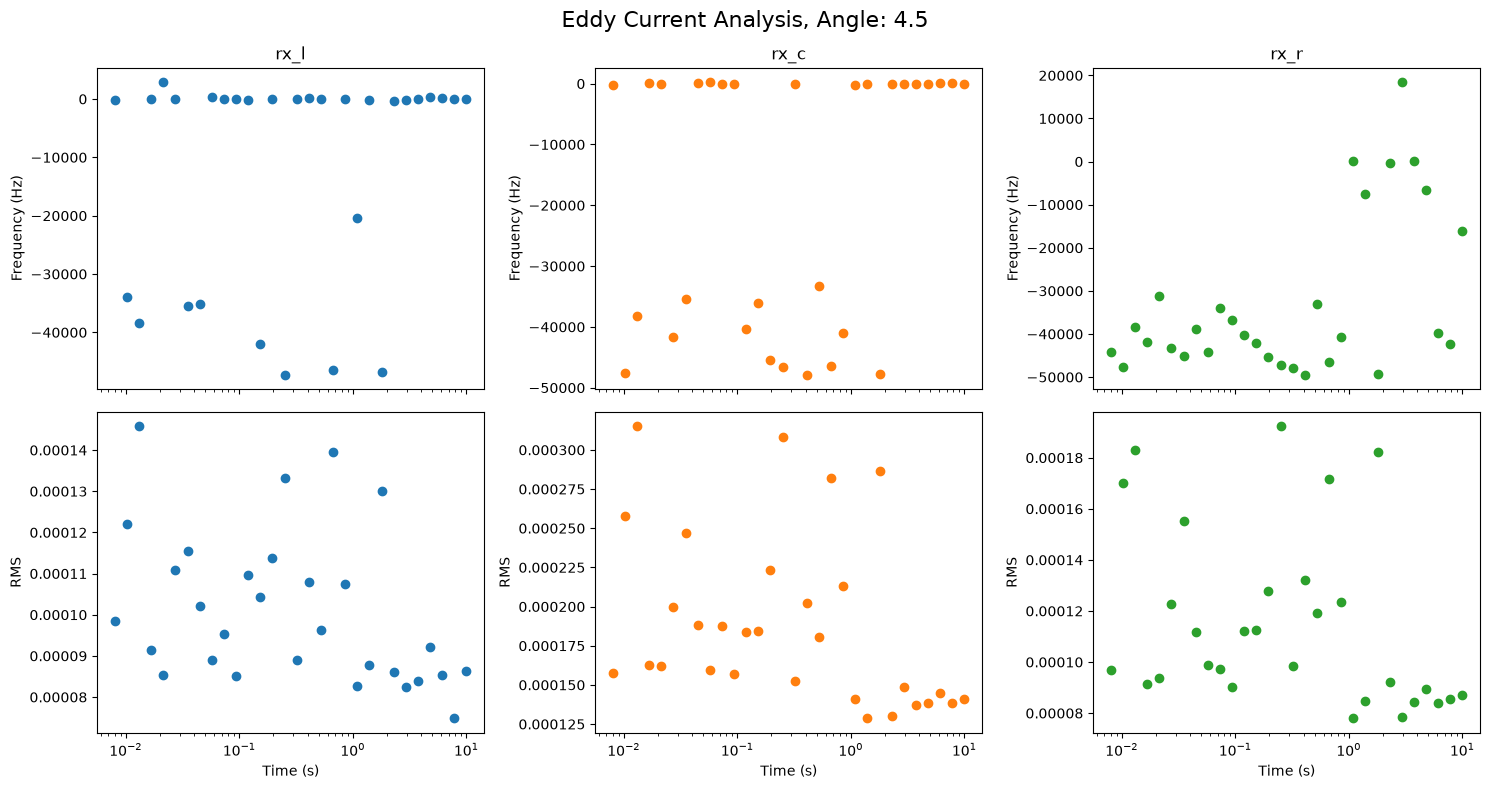

In [11]:
ZERO_FILLING = 200000
angle = 4.5
# REMAKING THE INDEXING OF THE ACQs
times = np.geomspace(seq.par.t_wait, seq.par.t_end, num=seq.par.n_pulses)

times = np.concatenate(([0], times))
list_ = []
n_acq = seq.par.n_pulses+1

for i_pulse in range(n_acq):
    list_.append([(i_pulse+1 + n_acq * i_chan) for i_chan, rx in enumerate(seq.par.rx_chan_list)]) # +1 as started on 1 index not zero

print(list_)

df_idx = pd.DataFrame(list_, columns = ["rx_l", "rx_c", "rx_r"])
df_idx["times (s)"] = times
# display(df_idx[0:3])
apodization = 100

df_freq = pd.DataFrame(df_idx["times (s)"], columns =["times (s)"]) # skip first one as is for gradient calibration
df_rms = pd.DataFrame(df_idx["times (s)"],columns = ["times (s)"])

# CALCULATING THE FREQ AND RMS
for rx in df_idx.columns[0:3]: # dont do times column
    df = df_idx[rx]
    freq_c  = []
    rms_list  = []
    for key in df:        
        t_dw = seq.par.t_dw
        data = seq.data_map[key]
        time = np.linspace(t_dw,len(data)*t_dw, len(data))
        window = np.exp(-np.pi*apodization*time)
        processed_signal = np.concatenate((seq.data_map[key]*window, np.zeros(ZERO_FILLING)))
        freq, img = get_freq_spectrum(signal = processed_signal, dwell_time= seq.par.t_dw)
            
        RMS = np.sqrt(np.mean(np.abs(data)**2)) # plot this against time for each acq to see how the amplitude changes over time and checks that the flip angle leads to steady-state
        
        spectrum_mag = np.abs(img)
        peak_index = np.argmax(spectrum_mag)
        centre_freq = freq[peak_index]
        freq_c.append(centre_freq)
        rms_list.append(RMS)
        
    df_freq[rx] = freq_c
    df_rms[rx] = rms_list

# PLOTTING TO SHOW THE FREQ AND RMS
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

cols = ["rx_l", "rx_c", "rx_r"]
colors = {
    "rx_l": "tab:blue",
    "rx_c": "tab:orange",
    "rx_r": "tab:green",
}

for i, col in enumerate(cols):

    # Frequency row
    axes[0, i].scatter(
    df_freq["times (s)"][1:],
        df_freq[col][1:],
        color=colors[col]
    )
    axes[0, i].set_xscale("log")
    axes[0, i].set_title(col)
    axes[0, i].set_ylabel("Frequency (Hz)")

    # RMS row
    
    axes[1, i].scatter(df_rms["times (s)"][1:], df_rms[col][1:], color=colors[col])
    axes[1, i].set_xscale("log")
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("RMS")

fig.suptitle(f"Eddy Current Analysis, Angle: {angle}", fontsize=16)
plt.tight_layout()
plt.show()